# BIOINF 580 — Lab 3
### 10/21/26
### GSI: Morgen Henry


---

# 0. Setup Reminder

Before starting this lab, please verify that your environment is ready.

1. **Check that all required packages are installed**  
   Run the following code cell to make sure you have these packages available:  
   `pandas`, `numpy`, `scikit-learn`, and `matplotlib`.

   - Note: the import name is `sklearn`, but the conda package name is **`scikit-learn`**.
   - If any package is **missing**, open a terminal (or Anaconda Prompt) and activate your lab environment:
     ```bash
     conda activate bioinf580
     ```
   - Then install the missing packages:
     ```bash
     conda install pandas numpy scikit-learn matplotlib
     ```
   - After installation, make sure to **reselect the correct kernel (step 2 below) or restart Jupyter Notebook** if it is already opened.

2. **Select the correct Jupyter kernel**  
   When this notebook is open, go to the **top-right corner** of Jupyter Notebook  
   and choose **`bioinf580`** as your active kernel.

Once all packages are confirmed and the correct kernel is selected, you’re ready to begin the lab.


In [1]:
# Check that all required packages are installed and report their versions

# import name -> conda/pip package name (they differ for scikit-learn!)
required_packages = {"pandas": "pandas", "numpy": "numpy", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing = []

print("Checking your Python environment...\n")

for pkg, conda_name in required_packages.items():
    try:
        module = __import__(pkg)
        version = getattr(module, "__version__", "unknown")
        print(f"[OK] {pkg} (version {version}) is installed.")
    except ImportError:
        print(f"[X] {pkg} is NOT installed.")
        missing.append(conda_name)

if missing:
    print("\nWARNING: Missing packages detected:", ", ".join(missing))
    print("Please open a terminal and run:")
    print("  conda activate bioinf580")
    print("  conda install " + " ".join(missing))
    print("\nAfter installation, close and reopen JupyterLab, then reselect the bioinf580 kernel.")
else:
    print("\nAll required packages are installed and ready to use!")


Checking your Python environment...



[OK] pandas (version 3.0.5) is installed.
[OK] numpy (version 2.5.3) is installed.


[OK] sklearn (version 1.9.1) is installed.
[OK] matplotlib (version 3.11.2) is installed.

All required packages are installed and ready to use!


---

# Part 1 – Clustering (Unsupervised Learning)

## 1.1 Recap: K-Means Clustering

K-Means is one of the simplest and most widely used methods for **unsupervised clustering** —  
it groups data points into *$K$* clusters based on how close they are to each other.

### Core Idea
K-Means tries to find *$K$* cluster centers (called **centroids**) so that:
- Points in the same cluster are as similar as possible, and  
- Points in different clusters are as different as possible.

It does this by measuring how far each point is from each centroid and repeatedly adjusting the centroids to better represent the data. Formally, it minimizes the **within-cluster sum of squared distances** (called *inertia* in scikit-learn).

[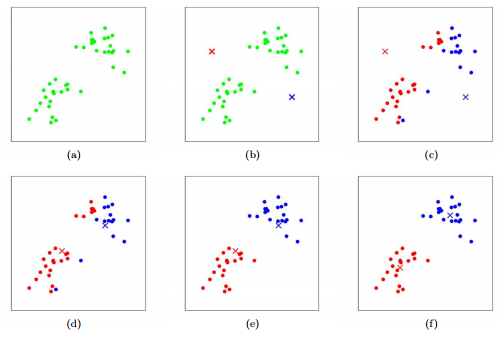](https://stanford.edu/~cpiech/cs221/handouts/kmeans.html)

### How It Works
1. **Initialization:**  
   Start by choosing *$K$* initial cluster centers. (scikit-learn's default, `k-means++`, picks them randomly but spreads them out, which usually gives better results than purely random picks.)

2. **Assignment step:**  
   For each data point, find which centroid it’s closest to (using ordinary distance, like a ruler).  
   The point “joins” that cluster.

3. **Update step:**  
   Move each centroid to the average position of all points currently assigned to it.

4. **Repeat:**  
   Keep reassigning points and updating centroids until the cluster positions stop changing.

### In this section, we will:
1. Generate synthetic data using [`make_blobs`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html).  
2. Apply [`KMeans`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) from `sklearn.cluster`.  
3. Visualize the clusters and the centroid positions.  
4. Test K-Means on non-spherical data using [`make_moons`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html) to see where it fails.


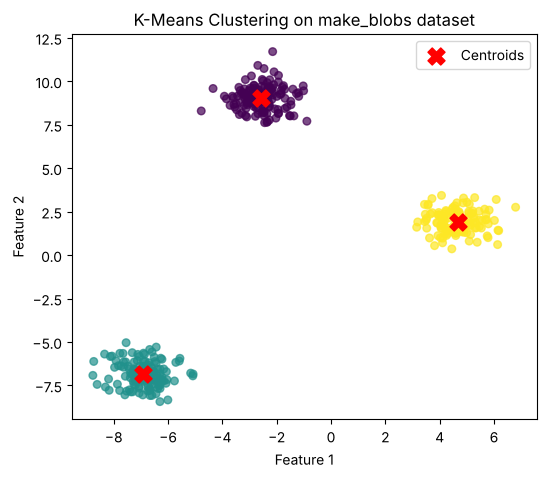

In [2]:
# === 1.1 K-Means recap ===

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans

# Create a simple 2D dataset
X_blobs, _ = make_blobs(n_samples=400, cluster_std=0.7, random_state=42)
# print("Dataset shape:", X_blobs.shape)

# Fit K-Means
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans.fit(X_blobs)
y_pred = kmeans.predict(X_blobs)
# y_pred = kmeans.fit_predict(X_blobs)

# Plot the results
plt.figure(figsize=(6, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_pred, s=30, cmap="viridis", alpha=0.7)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c="red", s=150, marker="X", label="Centroids")
plt.title("K-Means Clustering on make_blobs dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()


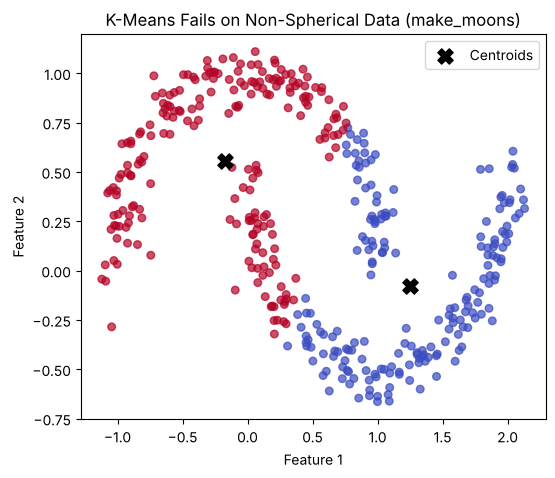

In [3]:
# Demonstrate K-Means limitation using make_moons (non-spherical clusters)

X_moons, _ = make_moons(n_samples=400, noise=0.08, random_state=42)
# print("Moon Dataset shape:", X_moons.shape)

kmeans_moon = KMeans(n_clusters=2, n_init=10, random_state=42)
y_moon_pred = kmeans_moon.fit_predict(X_moons)

plt.figure(figsize=(6, 5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moon_pred, s=30, cmap="coolwarm", alpha=0.7)
plt.scatter(kmeans_moon.cluster_centers_[:, 0], kmeans_moon.cluster_centers_[:, 1],
            c="black", s=120, marker="X", label="Centroids")
plt.title("K-Means Fails on Non-Spherical Data (make_moons)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()


### Key Notes
- **Hard clustering:**  
  Each point belongs to exactly one cluster (no overlap).

- **Spherical assumption:**  
  K-Means uses simple straight-line distance (Euclidean distance).  
  This makes it work best when clusters are roughly **circular (in 2D)** or **spherical (in higher dimensions)** and have similar sizes.  
  It struggles with elongated, curved, or unevenly sized clusters.

- **Initialization sensitivity:**  
  Since K-Means starts with random centroids, different starting points can lead to slightly different results.  
  That’s why it’s often run several times and the best result is kept.

- **You must choose $K$ in advance:**  
  K-Means will happily return $K$ clusters even if the data has no such structure. Methods like the elbow plot or silhouette score can help, and a GMM can use BIC (you will try this below).

- **Feature scaling:**  
  If one feature has much larger values than others, it will dominate the distance calculation.  
  To avoid this, we usually standardize or normalize features before clustering.

---

## 1.2 Gaussian Mixture Model (GMM)

K-Means assumes clusters are **perfectly spherical** and uses simple, straight-line **Euclidean distance** to decide which cluster a point belongs to.

However, many real-world datasets have clusters that are **elliptical** (like ovals), **overlapping**, or have **different sizes**. To handle these complex shapes, we use a **Gaussian Mixture Model (GMM)**—a much more flexible, **probabilistic extension** of K-Means.

### Core Idea
A GMM assumes the data is generated from a mixture of *$K$* different **Gaussian (bell curve) clusters**.

Instead of assigning a point definitively to one cluster (a "hard" assignment), GMM calculates the **probability** of that data point (x) belonging to each of the *$K$* clusters.

$$
p(x) = \sum_{k=1}^{K} \phi_k \, \mathcal{N}(x \mid \mu_k, \Sigma_k)
$$

**GMM determines three things for each cluster $k$:**
1.  **Mixing Weight ($\phi_k$):** How large the cluster is (its proportion of the total data).
2.  **Mean ($\mu_k$):** The center location of the cluster.
3.  **Covariance Matrix ($\Sigma_k$):** The shape, size, and orientation (tilt) of the cluster.

### Training via Expectation–Maximization (EM)
The GMM is trained using a sophisticated two-step process that repeats until the model stabilizes:

1.  **E-step (Expectation):** Calculate the **probability** that each data point belongs to each cluster, based on the current cluster parameters ($\mu_k, \Sigma_k$).
2.  **M-step (Maximization):** Use these calculated **probabilities** to update and find the best new values for the center ($\mu_k$), shape ($\Sigma_k$), and size ($\phi_k$) of every cluster.
3.  Repeat until the model no longer improves.

### Key Differences vs. K-Means
| Feature | **GMM** | **K-Means** |
|:--------|:--------|:-------------|
| Membership | **Soft** (**Probabilistic** assignment) | **Hard** (Point is either *in* or *out* of a cluster) |
| Cluster shape | **Elliptical** (variable shape and tilt) | **Spherical** (fixed, round shape) |
| Objective | **Maximize the overall likelihood** of seeing the data | Minimize within-cluster squared distance (inertia) |
| Output | Center, Shape, Size, plus **probabilities** for every point | Cluster labels and centers |

[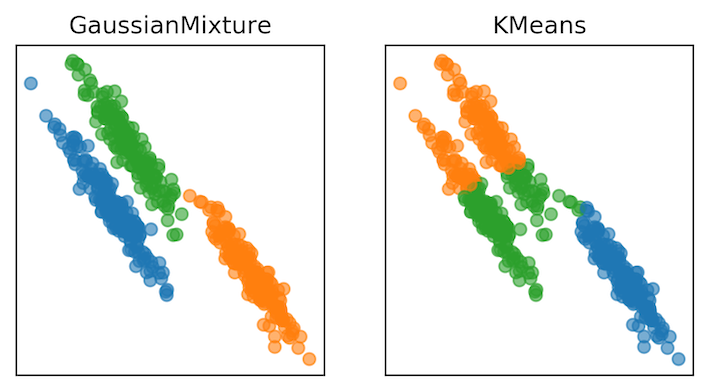](https://amueller.github.io/aml/03-unsupervised-learning/02-clustering-mixture-models.html)

### Relationship Between Mahalanobis Distance and GMM

Recall the **Mahalanobis distance**, which measures how far a point $x$ is from a distribution with mean $\mu$ and covariance $\Sigma$:

$$
\mathbf{D_M(x, \mu, \Sigma)} = \sqrt{\underbrace{\mathbf{(x - \mu)^{T} \Sigma^{-1} (x - \mu)}}_{\text{Squared Mahalanobis Distance}}}
$$

This distance naturally appears inside the **Gaussian probability density function** used by GMM:

$$
\mathbf{\mathcal{N}(x \mid \mu, \Sigma)} =
\frac{1}{\sqrt{(2\pi)^d |\Sigma|}} 
\exp\!\left(-\frac{1}{2}\underbrace{\mathbf{(x - \mu)^{T} \Sigma^{-1} (x - \mu)}}_{\text{Squared Mahalanobis Distance}}\right)
$$

So when GMM assigns probabilities to points, it is effectively measuring how close they are to each Gaussian’s center —  
but using the **Mahalanobis distance** instead of the Euclidean distance.

This means:
- **K-Means** uses Euclidean distance (assumes equal, spherical variance).  
- **GMM** uses Mahalanobis distance (accounts for covariance shape).  

That’s why GMM can model **elongated or tilted clusters**, while K-Means cannot.

> **Small caveat:** the Gaussian density also includes the mixing weight $\phi_k$ and the normalizing term $|\Sigma_k|$, so the cluster a point is assigned to is not simply the one with the smallest Mahalanobis distance. Mahalanobis distance is the *core* of the calculation, not the whole thing.

### In this section we will:
1.  Fit a GMM to the same synthetic dataset used for K-Means.
2.  Visualize the **soft cluster assignments** (probabilities) and compare them to the hard assignments from K-Means.
3.  Apply GMM to the famous **make\_moons** dataset where K-Means struggled, and observe whether GMM performs better.

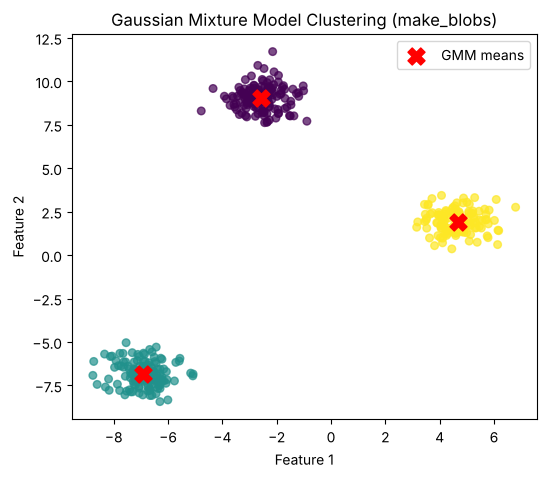

In [4]:
# === 1.2  Gaussian Mixture Model (GMM) ===
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

# Reuse the blob dataset created earlier
X = X_blobs  # from K-Means section

# Fit GMM
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
gmm.fit(X)
y_gmm = gmm.predict(X)

# Plot hard cluster assignments
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y_gmm, s=30, cmap='viridis', alpha=0.7)
plt.scatter(gmm.means_[:, 0], gmm.means_[:, 1], c='red', s=150, marker='X', label='GMM means')
plt.title("Gaussian Mixture Model Clustering (make_blobs)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()


In [5]:
probs = gmm.predict_proba(X)
print("Shape:", probs.shape, "(one probability per point, per component)")
print("Each row sums to 1:", np.allclose(probs.sum(axis=1), 1))
probs[:5].round(3)

Shape: (400, 3) (one probability per point, per component)
Each row sums to 1: True


array([[0., 1., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.]])

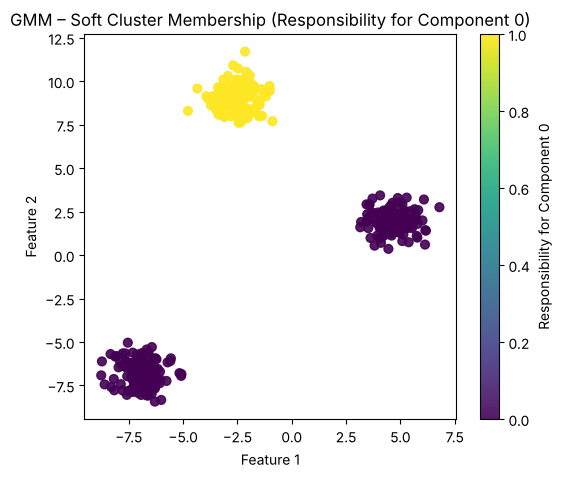

In [6]:
# Visualize soft cluster membership for one component
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=probs[:, 0], cmap='viridis', s=40, alpha=0.9)
# plt.scatter(X[:, 0], X[:, 1], c=probs[:, 1], cmap='viridis', s=40, alpha=0.9)
# plt.scatter(X[:, 0], X[:, 1], c=probs[:, 2], cmap='viridis', s=40, alpha=0.9)
plt.title("GMM – Soft Cluster Membership (Responsibility for Component 0)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.colorbar(label="Responsibility for Component 0")
plt.show()


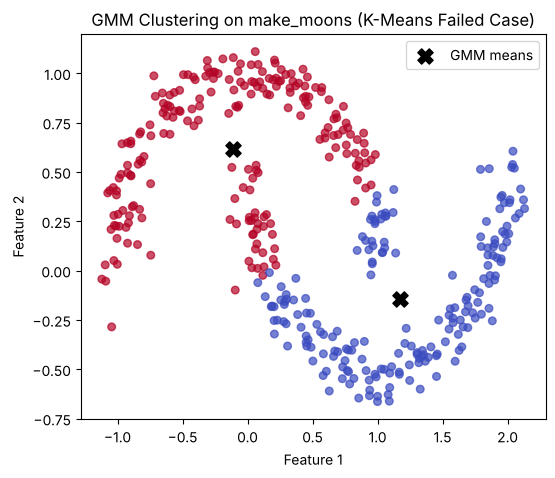

Adjusted Rand Index  K-Means: 0.23 | GMM: 0.45  (1.0 = perfect, 0 = random)


In [7]:
# === GMM applied to non-spherical clusters (make_moons) ===
from sklearn.datasets import make_moons

# Generate dataset
X_moons, y_moons_true = make_moons(n_samples=400, noise=0.08, random_state=42)

# Fit GMM with two components
gmm_moon = GaussianMixture(n_components=2, covariance_type='full', random_state=42)
gmm_moon.fit(X_moons)
y_moon_gmm = gmm_moon.predict(X_moons)

# Plot results
plt.figure(figsize=(6, 5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moon_gmm, s=30, cmap='coolwarm', alpha=0.7)
plt.scatter(gmm_moon.means_[:, 0], gmm_moon.means_[:, 1],
            c='black', s=120, marker='X', label='GMM means')
plt.title("GMM Clustering on make_moons (K-Means Failed Case)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()


# Labels are only used here to *score* the clustering (they were never given to the models)
from sklearn.metrics import adjusted_rand_score
print(f"Adjusted Rand Index  K-Means: {adjusted_rand_score(y_moons_true, y_moon_pred):.2f} | GMM: {adjusted_rand_score(y_moons_true, y_moon_gmm):.2f}  (1.0 = perfect, 0 = random)")


### What did we learn from `make_moons`?
GMM does a bit **better** than K-Means here (see the Adjusted Rand Index above), but it still does **not** recover the two moons. Each GMM component is a single Gaussian (one ellipse), and a crescent is not an ellipse.

So a more flexible *covariance* is not the same as a more flexible *shape*. For curved clusters you would reach for a different family of methods, such as **DBSCAN** or **spectral clustering**, or use more mixture components than true clusters.

**Take-away:** every model comes with assumptions. Choosing a model means asking whether your data plausibly satisfies them.

---
# Try It Yourself 1 — Use U-M GPT to write code (and check its work)

So far, the code was written for you. In practice you will often use an AI assistant to get a first draft of analysis code. This section shows how to do that **responsibly** with **U-M GPT**, the university's AI chat service.

> **Golden rule: an LLM's output is a *hypothesis*, not a result.** You are the author of anything you submit or publish, so you are responsible for every line. **Every piece of AI-generated code in this course must be verified by you before you use it.**

### What is U-M GPT?
U-M GPT (**umgpt.umich.edu**) is the University of Michigan's generative-AI chat service, available to active U-M students, faculty, and staff. It gives you access to hosted large language models, run by ITS under university data-protection policies.

It is a **general-purpose** assistant. It has **not** read your notebook, it does not know the names of your variables, and it is **not** tied to the scikit-learn documentation. That means (1) you must put the relevant context into your prompt, and (2) it **can be wrong, out of date, or invent function names and arguments** that look perfectly plausible. Catching that is the point of this section. ITS also limits how many prompts you can send per hour, so write each prompt carefully instead of firing off many vague ones.

### Before you start: privacy and course rules
- Sign in at **umgpt.umich.edu** with your uniqname and UMICH password, then complete MFA.
- Only paste **synthetic or public data** (like this lab's `make_blobs` data). **Never paste patient data, restricted research data, other people's work, or anything sensitive.** Check the ITS Sensitive Data Guide and the ITS AI Services privacy notice for what U-M GPT permits.
- Follow the course syllabus policy on AI tools, and be ready to say where you used an AI assistant.

### The 6-step workflow

| Step | What you do | Why |
|:----:|:------------|:----|
| **1. Open** | Go to **umgpt.umich.edu**, sign in, and start a new chat. | Uses the university-approved service, not a random website. |
| **2. Prompt** | Write a specific prompt: *context + task + constraints + output format* (template below). U-M GPT cannot see your notebook, so describe your data. | Vague prompts give vague, often wrong, code. |
| **3. Read** | Read the code line by line **before running it**. Ask U-M GPT to explain anything you do not understand. | If you cannot explain a line, you cannot defend it. |
| **4. Run** | Paste it into a cell and run it. Fix errors by giving U-M GPT the **full error message** (not just "it broke"). | Errors are free information; running is cheap. |
| **5. Verify** | Apply the checklist below. At least one check must be **independent** of the AI. | A confident answer is not a correct answer. |
| **6. Log** | Note your prompt, what you changed, and what you verified (template at the end). | Reproducibility and honesty. |

#### A good prompt has four parts
```text
CONTEXT:  I have a 2D NumPy array X_aniso of shape (500, 2) with elongated clusters,
          and true labels y_aniso (for evaluation only). I use scikit-learn.
TASK:     Fit K-Means (k=3) and a Gaussian mixture model (3 components, full covariance)
          and plot both clusterings side by side.
CONSTRAINTS: Use random_state=42, n_init=10 for K-Means and n_init=5 for the GMM.
          Do not use any library other than numpy, matplotlib, scikit-learn.
OUTPUT:   One runnable code cell with comments. Tell me which scikit-learn
          functions you used so I can check them in the documentation.
```

### The verification checklist

| # | Check | How to do it | Red flag |
|:-:|:------|:-------------|:---------|
| 1 | **Does it do what I asked?** | Re-read your prompt, then the code. Is every requirement (k, seeds, covariance type, plot type) present? | Silently different parameters or an extra step you never asked for |
| 2 | **Are the functions/arguments real?** | Look each one up in the [scikit-learn docs](https://scikit-learn.org/stable/api/index.html). U-M GPT is not connected to the docs, so this check matters even more. | Made-up arguments, wrong import path, deprecated API |
| 3 | **Do shapes and types make sense?** | Print `.shape`, `.dtype`, `np.unique(labels)`. | 2 clusters when you asked for 3, wrong axis |
| 4 | **Does it pass a sanity check you can reason about?** | Use data where you *know* the answer (here: the true labels, the number of blobs you generated). | A result that contradicts what you can see in the plot |
| 5 | **Is it reproducible?** | Re-run the cell. Same output? Seeds set? | Different answer each run with no seed |
| 6 | **Does it agree with an independent method?** | Compare to your own short version, to a different metric, or to results from the lab above. | Disagreement you cannot explain |

### Step A: A dataset with elongated, tilted clusters
This is the data you will work with. We know the truth (3 blobs) because we generated it; that lets you *verify* what the AI gives you.

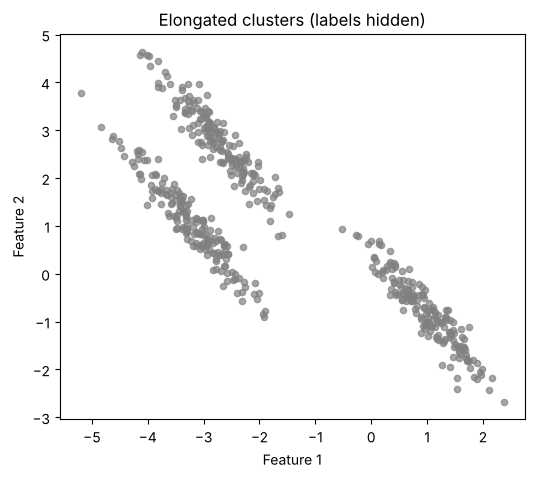

In [8]:
# Data for Try It Yourself 1: three blobs, stretched and rotated with a linear transform
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

X_raw, y_aniso = make_blobs(n_samples=500, centers=3, cluster_std=0.8, random_state=170)
transform = np.array([[0.6, -0.6], [-0.4, 0.8]])
X_aniso = X_raw @ transform          # shape (500, 2)

plt.figure(figsize=(6, 5))
plt.scatter(X_aniso[:, 0], X_aniso[:, 1], s=20, alpha=0.7, color="gray")
plt.title("Elongated clusters (labels hidden)")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.show()

### Step B: Spot the bug (a deliberately flawed "AI answer")
Below is the kind of code an assistant might hand you when asked *"choose the number of GMM components"*. It **runs without errors**, which is exactly why it is dangerous.

**Before you run it**, read it and write down (on paper or in a markdown cell) what you think could be wrong. Then run it and compare with the plot above, where you can count the blobs yourself.

In [9]:
# WARNING: INTENTIONALLY FLAWED example of AI-generated code. Do not reuse!
from sklearn.mixture import GaussianMixture

best_k, best_score = None, -np.inf
for k in range(1, 9):
    gmm_k = GaussianMixture(n_components=k, covariance_type="full").fit(X_aniso)
    score = gmm_k.score(X_aniso)          # average log-likelihood per sample
    if score > best_score:
        best_k, best_score = k, score

print("Best number of components:", best_k)

Best number of components: 8


<details>
<summary><b>Click to reveal what is wrong (try first!)</b></summary>

1. **Wrong criterion.** The (log-)likelihood almost always *increases* as you add components, because more components can fit the data more closely. Maximizing it just picks a number close to the largest `k` you tried. A criterion that **penalizes complexity**, such as **BIC** (`gmm.bic(X)`, *lower is better*) or AIC, is needed.
2. **No `random_state`/`n_init`.** The result can change from run to run, and EM can land in a poor local optimum.
3. It **failed check 4** of our checklist: the plot clearly shows 3 blobs, but the code answered with a much bigger number. A result you can contradict by eye should never be accepted.
</details>

### Step C: Your turn
Use U-M GPT (following the 6 steps) to get code that does **both** of these on `X_aniso`:

1. **Compare clusterings.** Fit K-Means (k=3) and a GMM (3 components, `covariance_type="full"`) and plot them **side by side** with the centers/means marked.
2. **Choose the number of components.** Fit GMMs for `k = 1, ..., 7` and plot **BIC vs. k**. Report the `k` that minimizes BIC.

Put the AI-generated code in the cell below. **Edit and annotate it** (add a comment on each line you checked in the docs). Then run the verification helper in the next cell.

In [10]:
# YOUR CODE HERE (paste U-M GPT's code, then read, edit, and verify it)
# Store your predicted labels in these variables so the checker below can find them:
#   labels_kmeans = ...   (array of length 500)
#   labels_gmm    = ...   (array of length 500)
#   best_k        = ...   (the k with the lowest BIC)

### Step D: Independent verification
This helper compares your results with the ground-truth labels `y_aniso`. This is an **independent** check: the answer key does not come from the AI. It uses the **Adjusted Rand Index (ARI)**, where 1.0 means the clustering matches the truth perfectly and about 0 means no better than random.

In [11]:
# Verification helper (read it, it is short!). Run AFTER your own cell above.
from sklearn.metrics import adjusted_rand_score

def verify_my_work():
    problems = []
    for name in ["labels_kmeans", "labels_gmm", "best_k"]:
        if name not in globals():
            problems.append(f"Variable `{name}` is not defined yet.")
    if problems:
        print("[X]", *problems, sep="\n   ")
        return

    for name in ["labels_kmeans", "labels_gmm"]:
        lab = np.asarray(globals()[name])
        ok_shape = lab.shape == (500,)
        n_clusters = len(np.unique(lab))
        ari = adjusted_rand_score(y_aniso, lab)
        print(f"{'[OK]' if ok_shape and n_clusters == 3 else '[X]'} {name}: shape={lab.shape}, "
              f"clusters found={n_clusters}, ARI vs. truth = {ari:.2f}")

    print(f"Note:  best_k from BIC = {best_k}   (compare with how many blobs you can count in the plot)")
    print()
    print("Now ask yourself:")
    print(" - Which method has the higher ARI, and does that match what you saw in the side-by-side plot?")
    print(" - Why is the GMM's advantage expected on THIS dataset?")
    print(" - Re-run your cell. Do you get identical numbers? (checklist item 5)")

verify_my_work()

### Step E: AI log and reflection
Fill in a short log. Honest logs matter more than perfect code.

| Item | Your notes |
|:-----|:-----------|
| Prompt(s) I used (paste the final version) | |
| What the AI got wrong or I had to change | |
| Docs pages I checked (function names) | |
| My independent check(s) and the result | |
| Anything I still do not understand | |

**Reflection questions** (answer in a markdown cell)
1. Did U-M GPT's first answer pass all six checks? What did you have to fix?
2. Which check would have caught the flawed code in Step B, and how?
3. In which situations would you *not* trust an AI-generated answer even after it runs, and what would you do instead?

**Your log and answers:**

*double-click to edit*

---

# Part 2 – Classification (Supervised Learning)

In the previous part, we explored **unsupervised learning**, where the goal was to find structure or groupings in unlabeled data (e.g., *K-Means*, *GMM*).  

Now we move to **supervised learning**, where each training example comes with a **label**.  
The goal is to learn a function that maps input features $X$ to output labels $y$ so we can **predict labels for new, unseen samples**.

### Key Concept

In supervised learning, the model learns from *examples*:

$$
\text{Given training data } \{(x_1, y_1), (x_2, y_2), \dots, (x_n, y_n)\},
$$

we want to find a function $f(x)$ that minimizes the error between predicted labels $\hat{y}_i = f(x_i)$ and the true labels $y_i$.

### Types of Supervised Learning
| Task | Output | Examples of Algorithms |
|:------|:--------|:----------------------|
| **Classification** | Discrete categories | Naïve Bayes, SVM, Neural Networks |
| **Regression** | Continuous values | Linear Regression, SVR, MLP Regressor |

### Connection to Part 1
| Aspect | **Unsupervised (Part 1)** | **Supervised (Part 2)** |
|:--------|:--------------------------|:-------------------------|
| Data available | Only $X$ | $X$ and $y$ |
| Goal | Discover patterns | Predict known labels |
| Examples | K-Means, GMM | Naïve Bayes, SVM, MLP |
| Decision boundaries | Emergent from geometry | Learned from labeled examples |

### In this part we will:
1. Use **Naïve Bayes** as a simple *probabilistic* classifier.  
2. Explore **Support Vector Machines (SVM)** as a *geometric, margin-based* classifier.  
3. Build a **Multilayer Perceptron (MLP)** as a *neural-network* classifier.  
4. Compare their behaviors and decision boundaries on the same dataset.
5. Score them with the **confusion-matrix metrics from the slides** (precision, sensitivity, specificity, F1, MCC, AUROC), not just accuracy.

> **Convention:** in `make_moons`, we call **class 1 the "positive" class** (think of it as "has the disease") and class 0 the negative class.

Before we begin, let’s load a dataset and prepare it for training and testing.


In [12]:
# === Part 2: Supervised Learning Setup ===

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# make_moons (nonlinear binary problem, 2 features so we can plot the decision boundary)
X_moons, y_moons = make_moons(n_samples=400, noise=0.25, random_state=42)
X, y = X_moons, y_moons

# Split and scale (fit the scaler on the TRAINING data only, to avoid data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")

# --- Helper used for every model in Part 2: plot a 2D decision boundary ---
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, cmap="coolwarm", alpha=0.25)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=30, alpha=0.7)
    plt.title(title, fontsize=12)
    plt.xlabel("Feature 1 (scaled)")
    plt.ylabel("Feature 2 (scaled)")
    plt.tight_layout()
    plt.show()


Training samples: 280 | Testing samples: 120


---

## 2.1 Naïve Bayes Classifier

The **Naïve Bayes (NB)** classifier is a simple but surprisingly effective method for **supervised classification**.  
It is based on **Bayes’ Theorem**, which allows us to estimate the probability of each class given the observed features.

### Bayes’ Theorem for Classification
For any class $y$ and feature vector $x$:

$$
P(y \mid x) = \frac{P(x \mid y) \, P(y)}{P(x)}
$$

Since $P(x)$ is constant for all classes, we can predict the most likely class as:

$$
\hat{y} = \arg\max_y \; P(x \mid y) \, P(y)
$$

### The "Naïve" Assumption
Naïve Bayes assumes that **all features are independent** given the class label.  
This simplifies the likelihood into a product of one-dimensional terms:

$$
P(x \mid y) = \prod_i P(x_i \mid y)
$$

Even though this assumption is rarely true, the model often works well in practice — especially when features provide complementary information.

### Key Points
- Fast to train and easy to interpret.  
- Works well for **text**, **categorical**, or **simple continuous** data.  
- Assumes features are independent (hence “naïve”).  
- Decision boundaries depend on the variant: **Multinomial/Bernoulli NB** give linear boundaries, while **Gaussian NB** (used below) gives *quadratic* (curved) boundaries unless the classes happen to share the same variances.

### In this section we will:
1. Train a **Gaussian** Naïve Bayes classifier on a labeled dataset (`make_moons`).  
2. Visualize its decision boundary.  
3. Discuss its strengths and limitations.


Accuracy: 0.8916666666666667


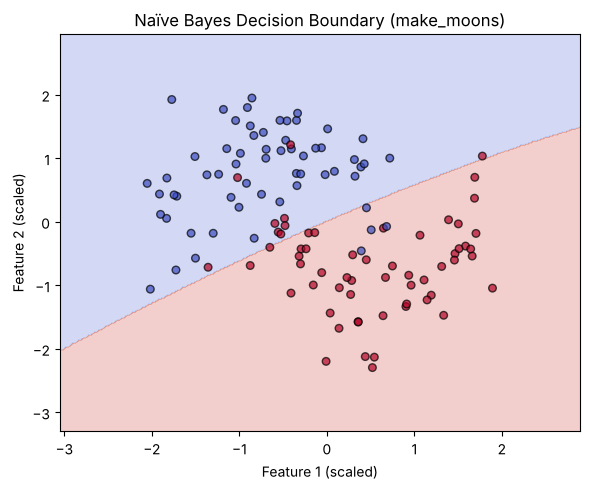

In [13]:
# === 2.1 Naïve Bayes ===
from sklearn.naive_bayes import GaussianNB

# Train model
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)

# Evaluate performance
print("Accuracy:", accuracy_score(y_test, y_pred))

plot_decision_boundary(gnb, X_test, y_test, "Naïve Bayes Decision Boundary (make_moons)")


### Connecting to the slides: the confusion matrix
Accuracy was one number. The slides showed that a **confusion matrix** breaks the same predictions into four counts (TP, FP, FN, TN), from which we can compute precision, sensitivity (recall), specificity, FPR, F1, and MCC.

> **Watch the orientation!** The slides put **predicted** classes on the rows and **actual** classes in the columns. scikit-learn's `confusion_matrix` does the opposite: **actual on the rows, predicted in the columns**, with the order `[[TN, FP], [FN, TP]]`. The cell below unpacks the four counts and rebuilds the slide-style table.

In [14]:
# === Confusion matrix and the metrics from the slides ===
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, matthews_corrcoef, roc_auc_score)
import pandas as pd

def report_metrics(y_true, y_pred, y_score=None):
    """Compute the slide metrics BY HAND from TP/FP/FN/TN (class 1 = positive)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()   # sklearn order: [[TN, FP], [FN, TP]]
    div = lambda a, b: a / b if b else float("nan")
    precision = div(tp, tp + fp)        # PPV: of those PREDICTED positive, how many really are positive
    recall    = div(tp, tp + fn)        # sensitivity / TPR: of those ACTUALLY positive, how many we caught
    out = {
        "Accuracy":    (tp + tn) / (tp + tn + fp + fn),
        "Precision":   precision,
        "Sensitivity": recall,
        "Specificity": div(tn, tn + fp),    # TNR
        "FPR":         div(fp, fp + tn),    # 1 - specificity
        "F1":          div(2 * precision * recall, precision + recall),
        "MCC":         div(tp * tn - fp * fn,
                           ((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)) ** 0.5),
    }
    if y_score is not None:
        out["AUROC"] = roc_auc_score(y_true, y_score)
    return out

# Counts for the Naive Bayes model from above
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("sklearn layout (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred))

print("\nSlide layout (rows = predicted, columns = actual):")
print(pd.DataFrame([[tp, fp], [fn, tn]],
                   index=["Predicted Positive", "Predicted Negative"],
                   columns=["Actual Positive", "Actual Negative"]))

m = report_metrics(y_test, y_pred, gnb.predict_proba(X_test)[:, 1])
print()
for k, v in m.items():
    print(f"{k:12s} {v:.3f}")

# Verify our hand-computed numbers against scikit-learn (never trust, always check!)
assert np.isclose(m["Precision"],   precision_score(y_test, y_pred))
assert np.isclose(m["Sensitivity"], recall_score(y_test, y_pred))
assert np.isclose(m["F1"],          f1_score(y_test, y_pred))
assert np.isclose(m["MCC"],         matthews_corrcoef(y_test, y_pred))
print("\nHand-computed metrics match scikit-learn.")

sklearn layout (rows = actual, columns = predicted):
[[56  4]
 [ 9 51]]

Slide layout (rows = predicted, columns = actual):


                    Actual Positive  Actual Negative
Predicted Positive               51                4
Predicted Negative                9               56

Accuracy     0.892
Precision    0.927
Sensitivity  0.850
Specificity  0.933
FPR          0.067
F1           0.887
MCC          0.786
AUROC        0.965



Hand-computed metrics match scikit-learn.


**Think about it (discuss with a neighbor):**
- Read off TP, FP, FN, and TN. Do they add up to the 120 test samples? Does `(TP + TN) / 120` equal the accuracy printed above?
- Which metric answers *"of the points we flagged as positive, how many really were?"* Which answers *"of the truly positive points, how many did we catch?"* (Slide trick: with the table in slide orientation, **precision divides by a row; sensitivity and specificity divide by a column**.)
- If class 1 meant "has cancer", which would you worry about more here, the FPs or the FNs?

---

## 2.2 Support Vector Machine (SVM)

**Support Vector Machines** are **geometric, margin-based** classifiers.  
They find the hyperplane that **maximizes the margin** between classes.

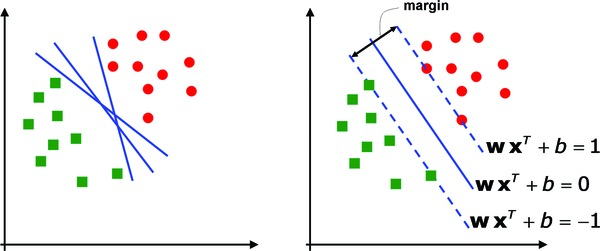

### Core Idea

Given labeled training data $\{(x_i, y_i)\}$, a **Support Vector Machine (SVM)** learns a decision function that separates the two classes with the **largest possible margin**, while allowing some classification errors to achieve better generalization.  
The trade-off between **margin width** and **misclassification penalty** is controlled by a positive parameter $C$:

$$
C > 0
$$

- **Small $C$** → the model is **lenient**, allowing more misclassifications to keep a **wider, smoother margin** (better generalization).  
- **Large $C$** → the model is **strict**, heavily penalizing misclassifications and trying to **classify every training sample correctly**, which can lead to overfitting.  

In practice, $C$ is often tuned on a logarithmic scale (e.g., $0.001, 0.01, 0.1, 1, 10, 100$) to find the best balance. 

### Kernels (nonlinear SVM)
When classes are not linearly separable, SVM uses a **kernel** to implicitly map data into a higher-dimensional space:

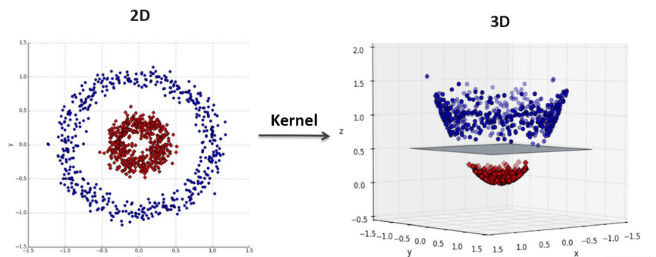

Below, we’ll train and visualize SVMs using **three common kernels**:
1. **Linear**
2. **Polynomial**
3. **RBF (Radial Basis Function)**

In [15]:
from sklearn.svm import SVC


#### 2.2.1 Linear Kernel
- **Idea:** Separates the classes using a **straight line (or hyperplane)**.
- **When to use:** Data is roughly linearly separable or has many features.
- **Main hyperparameter:**  
  - `C` — controls how strictly the model avoids misclassifications (large `C` = stricter).

SVM (Linear Kernel) — Accuracy: 0.892


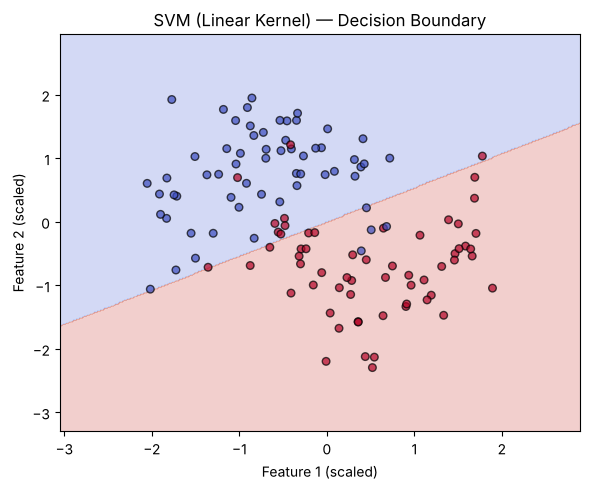

In [16]:
# --- Linear SVM ---
svm_linear = SVC(kernel='linear', C=1.0, random_state=42)
svm_linear.fit(X_train, y_train)
y_pred = svm_linear.predict(X_test)
acc_linear = accuracy_score(y_test, y_pred)
print(f"SVM (Linear Kernel) — Accuracy: {acc_linear:.3f}")

plot_decision_boundary(svm_linear, X_test, y_test,
                       "SVM (Linear Kernel) — Decision Boundary")


#### 2.2.2 Polynomial Kernel
- **Idea:** Allows the decision boundary to be **curved** by combining existing features (like squares or cubes).  
  This lets SVM handle moderately nonlinear relationships by mapping data into a higher-dimensional feature space.
- **When to use:** When the relationship between classes is **smoothly curved**, not purely linear or highly irregular.

##### Main Hyperparameters

| Hyperparameter | What it Controls | Typical Range | Larger Value Means... | Analogy | Suggested Starting Value |
|----------------|------------------|----------------|------------------------|----------|----------------------------|
| **`C`** | Penalty for misclassification (strictness) | $$10^{-3} \text{ to } 10^{3}$$ | Stricter fit, smaller margin, may overfit | **Strict vs. lenient teacher** — high `C` = perfectionist | $$C = 1.0$$ |
| **`degree`** | Complexity of polynomial (how many bends/curves) | $$2 \text{ to } 5$$ | More flexible, captures complex curves, risk of overfitting | **Number of bends in a flexible wire** | $$\text{degree} = 3$$ |
| **`gamma`** | Scale applied to the dot product $\langle x, x'\rangle$ inside the kernel $(\gamma\langle x, x'\rangle + \text{coef0})^{\text{degree}}$ | $10^{-3} \text{ to } 10$ | Larger = the kernel values grow faster, so the boundary can bend more sharply (and overfit more easily) | **Volume knob** on the feature interactions | $\text{gamma} = \text{"scale"}$ (auto-adjusted) |
| **`coef0`** | Constant added inside the kernel; balances **lower-order** against **higher-order** terms | $0 \text{ to } 10$ | Larger = lower-order (more linear) terms carry more weight | **Blend knob**: how straight vs. curved the line is | $\text{coef0} = 0.0$ |

**In short:**  
- `C` → how strictly the model avoids misclassification.  
- `degree` → how many "bends" the decision boundary can have.  
- `gamma` → how strongly feature interactions are scaled inside the kernel (for the **RBF** kernel below, it instead sets how far each point’s influence reaches).  
- `coef0` → how much linear vs. nonlinear behavior to mix in. 


SVM (Polynomial Kernel, degree=3) — Accuracy: 0.867


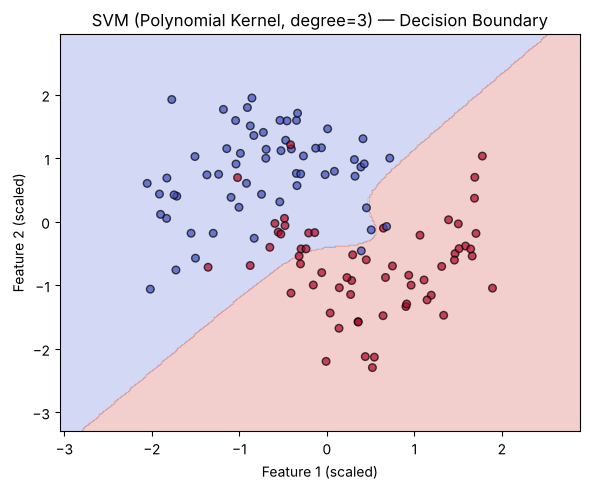

In [17]:
# --- Polynomial SVM ---
svm_poly = SVC(kernel='poly', C=1.0, degree=3, gamma='scale', coef0=0.0, random_state=42)
svm_poly.fit(X_train, y_train)
y_pred = svm_poly.predict(X_test)
acc_poly = accuracy_score(y_test, y_pred)
print(f"SVM (Polynomial Kernel, degree=3) — Accuracy: {acc_poly:.3f}")

plot_decision_boundary(svm_poly, X_test, y_test,
                       "SVM (Polynomial Kernel, degree=3) — Decision Boundary")


#### 2.2.3 RBF (Radial Basis Function / Gaussian) Kernel
- **Idea:** Measures similarity based on **distance** — points that are close together are considered similar, while distant points are treated as unrelated.  
  This allows SVM to form **smooth, flexible, and highly nonlinear decision boundaries** that can wrap around complex data shapes.
- **When to use:** When the data pattern is **clearly nonlinear or irregular**, and simpler kernels (like linear or polynomial) fail to separate the classes well.

##### Main Hyperparameters

| Hyperparameter | What it Controls | Typical Range | Larger Value Means... | Analogy | Suggested Starting Value |
|----------------|------------------|----------------|------------------------|----------|----------------------------|
| **`C`** | Penalty for misclassification (strictness) | $$10^{-3} \text{ to } 10^{3}$$ | Stricter fit, smaller margin, may overfit | **Strict vs. lenient teacher** — high `C` = perfectionist | $$C = 1.0$$ |
| **`gamma`** | Influence range of each data point | $$10^{-3} \text{ to } 10$$ | Higher = more local influence → sharper, more detailed boundaries | **Light bulb radius** — large `gamma` = sharp glow | $$\text{gamma} = \text{"scale"}$$ (auto-adjusted) |

**In short::**  
- `C` decides **how strict** the model is about classification errors.  
- `gamma` decides **how far each training point “reaches”** to influence others.


SVM (RBF Kernel) — Accuracy: 0.942


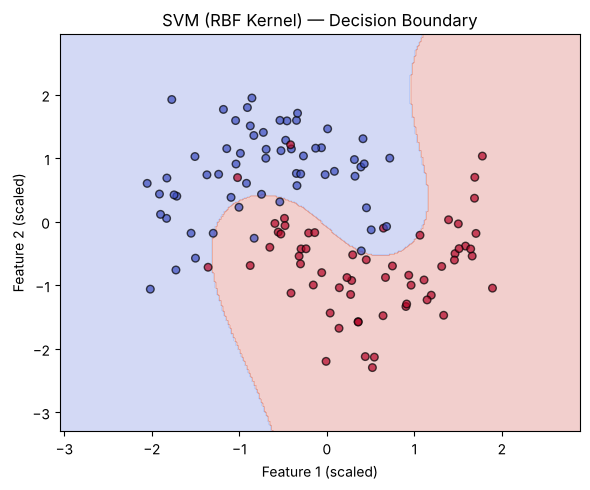

In [18]:
# --- RBF SVM ---
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_rbf.fit(X_train, y_train)
y_pred = svm_rbf.predict(X_test)
acc_rbf = accuracy_score(y_test, y_pred)
print(f"SVM (RBF Kernel) — Accuracy: {acc_rbf:.3f}")

plot_decision_boundary(svm_rbf, X_test, y_test,
                       "SVM (RBF Kernel) — Decision Boundary")


### How to read these accuracy numbers
Our test set has only **120 samples**, so **one** misclassified point changes accuracy by about **0.8 percentage points**. All of these models also saw a **single** train/test split. A gap of one or two points (for example 0.892 vs. 0.867) is therefore weak evidence that one model is truly better than another.

Notice also that the RBF kernel is clearly ahead here, which *is* a more meaningful gap, and it makes sense: the classes are two interleaving crescents, which no straight line separates well. Accuracy is also just one summary of the confusion matrix. Later you will compare models with the other metrics from the slides, and see how to compare them more fairly (cross-validation and repeated seeds).

---
# Try It Yourself 2 — Tune the RBF SVM without peeking at the test set

The RBF SVM above used default-ish settings (`C=1.0`, `gamma='scale'`). Can we do better by tuning them? The rule of the game:

> **The test set is used exactly once, at the very end.** All tuning decisions are made with **cross-validation on the training set only.**

**Your tasks**
1. Define a grid, for example `C` in `[0.01, 0.1, 1, 10, 100]` and `gamma` in `[0.01, 0.1, 1, 10, 100]`.
2. Use [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) with 5-fold cross-validation on `X_train`, `y_train`.
3. Plot the mean cross-validated accuracy as a **heatmap** (rows = `C`, columns = `gamma`).
4. Report the best parameters, then evaluate the refit model on `X_test` **once**.
5. Plot its decision boundary with `plot_decision_boundary`.
6. Use `report_metrics` (from the Naïve Bayes section) to get the tuned model's precision, sensitivity, and specificity on the test set.

**Questions to answer in a markdown cell**
- (a) In the heatmap, which corner looks like **underfitting** and which looks like **overfitting**? What visual clue tells you?
- (b) Is the tuned model's *test* accuracy better than the default RBF model's (0.942)? If not, why might that be, given what we said about a 120-sample test set?
- (c) Why would it be a mistake to pick `C` and `gamma` by looking at test accuracy?
- (d) Is the tuned model better at avoiding false positives or false negatives? Would you care about that difference if class 1 meant "has cancer"?

*(Using U-M GPT for this one is optional. If you do, follow the same verification checklist from Try It Yourself 1.)*

In [19]:
# YOUR CODE HERE (Try It Yourself 2)
# Hint: GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5).fit(X_train, y_train)
#       grid.cv_results_['mean_test_score'] holds one score per (C, gamma) pair

**Your answers (a)–(c):**

*double-click to edit*

---

## 2.3 Multilayer Perceptron (MLP)

The **Multilayer Perceptron (MLP)** is a basic form of **artificial neural network** used for supervised learning.  
It can model complex, nonlinear relationships between features and labels.

### Core Idea
An MLP consists of **layers of neurons**, where each neuron performs:
1. A **linear transformation** of its inputs (weighted sum plus bias), and  
2. Applies a nonlinear **activation function** to decide its output.

Each layer passes its output to the next, allowing the network to learn hierarchical feature representations.

> **scikit-learn detail:** in `MLPClassifier`, the `activation=` argument sets the activation of the **hidden layers** only. The output layer is chosen automatically: **logistic** for binary problems and **softmax** for multi-class problems. Everything below compares *hidden-layer* activations.

[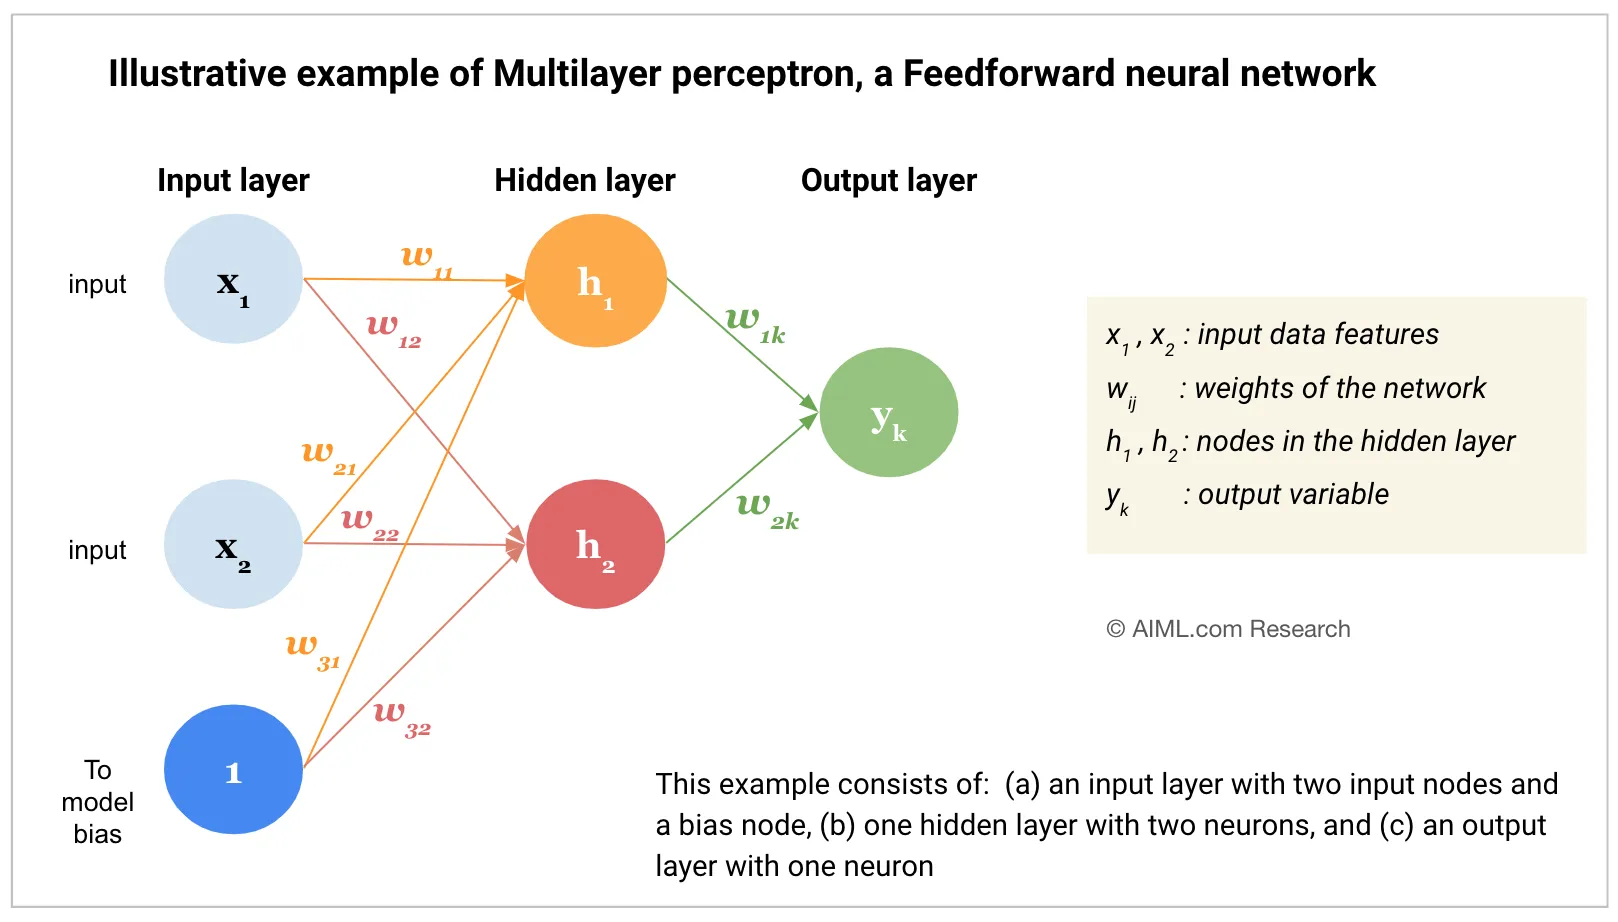](https://aiml.com/what-is-a-multilayer-perceptron-mlp/)

[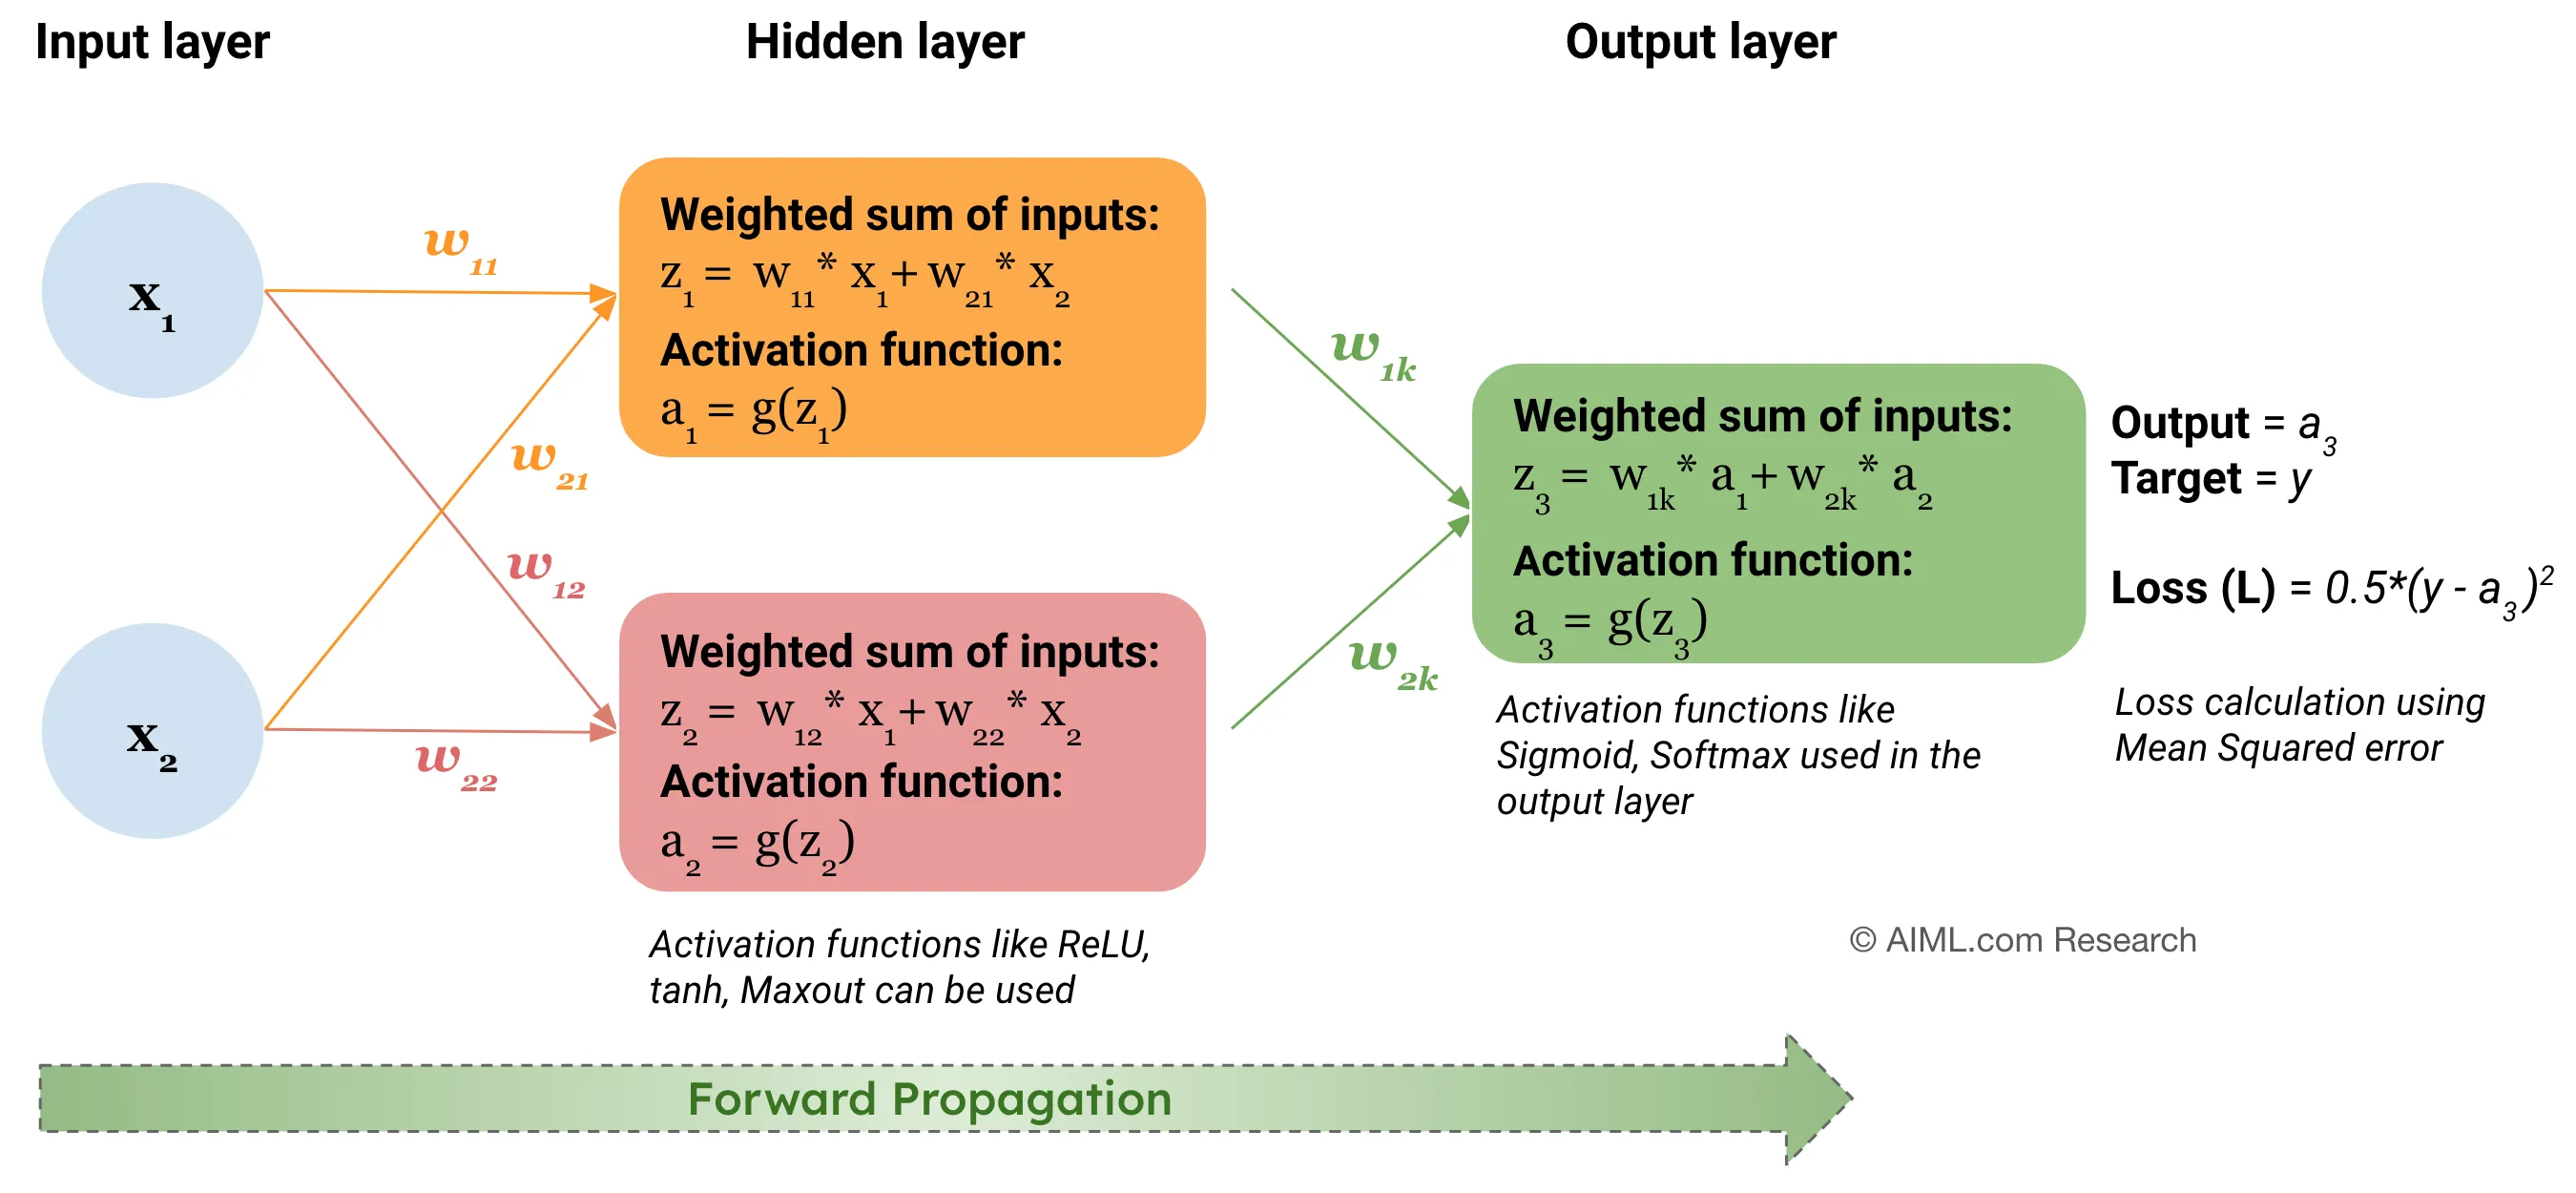](https://aiml.com/what-is-a-multilayer-perceptron-mlp/)

[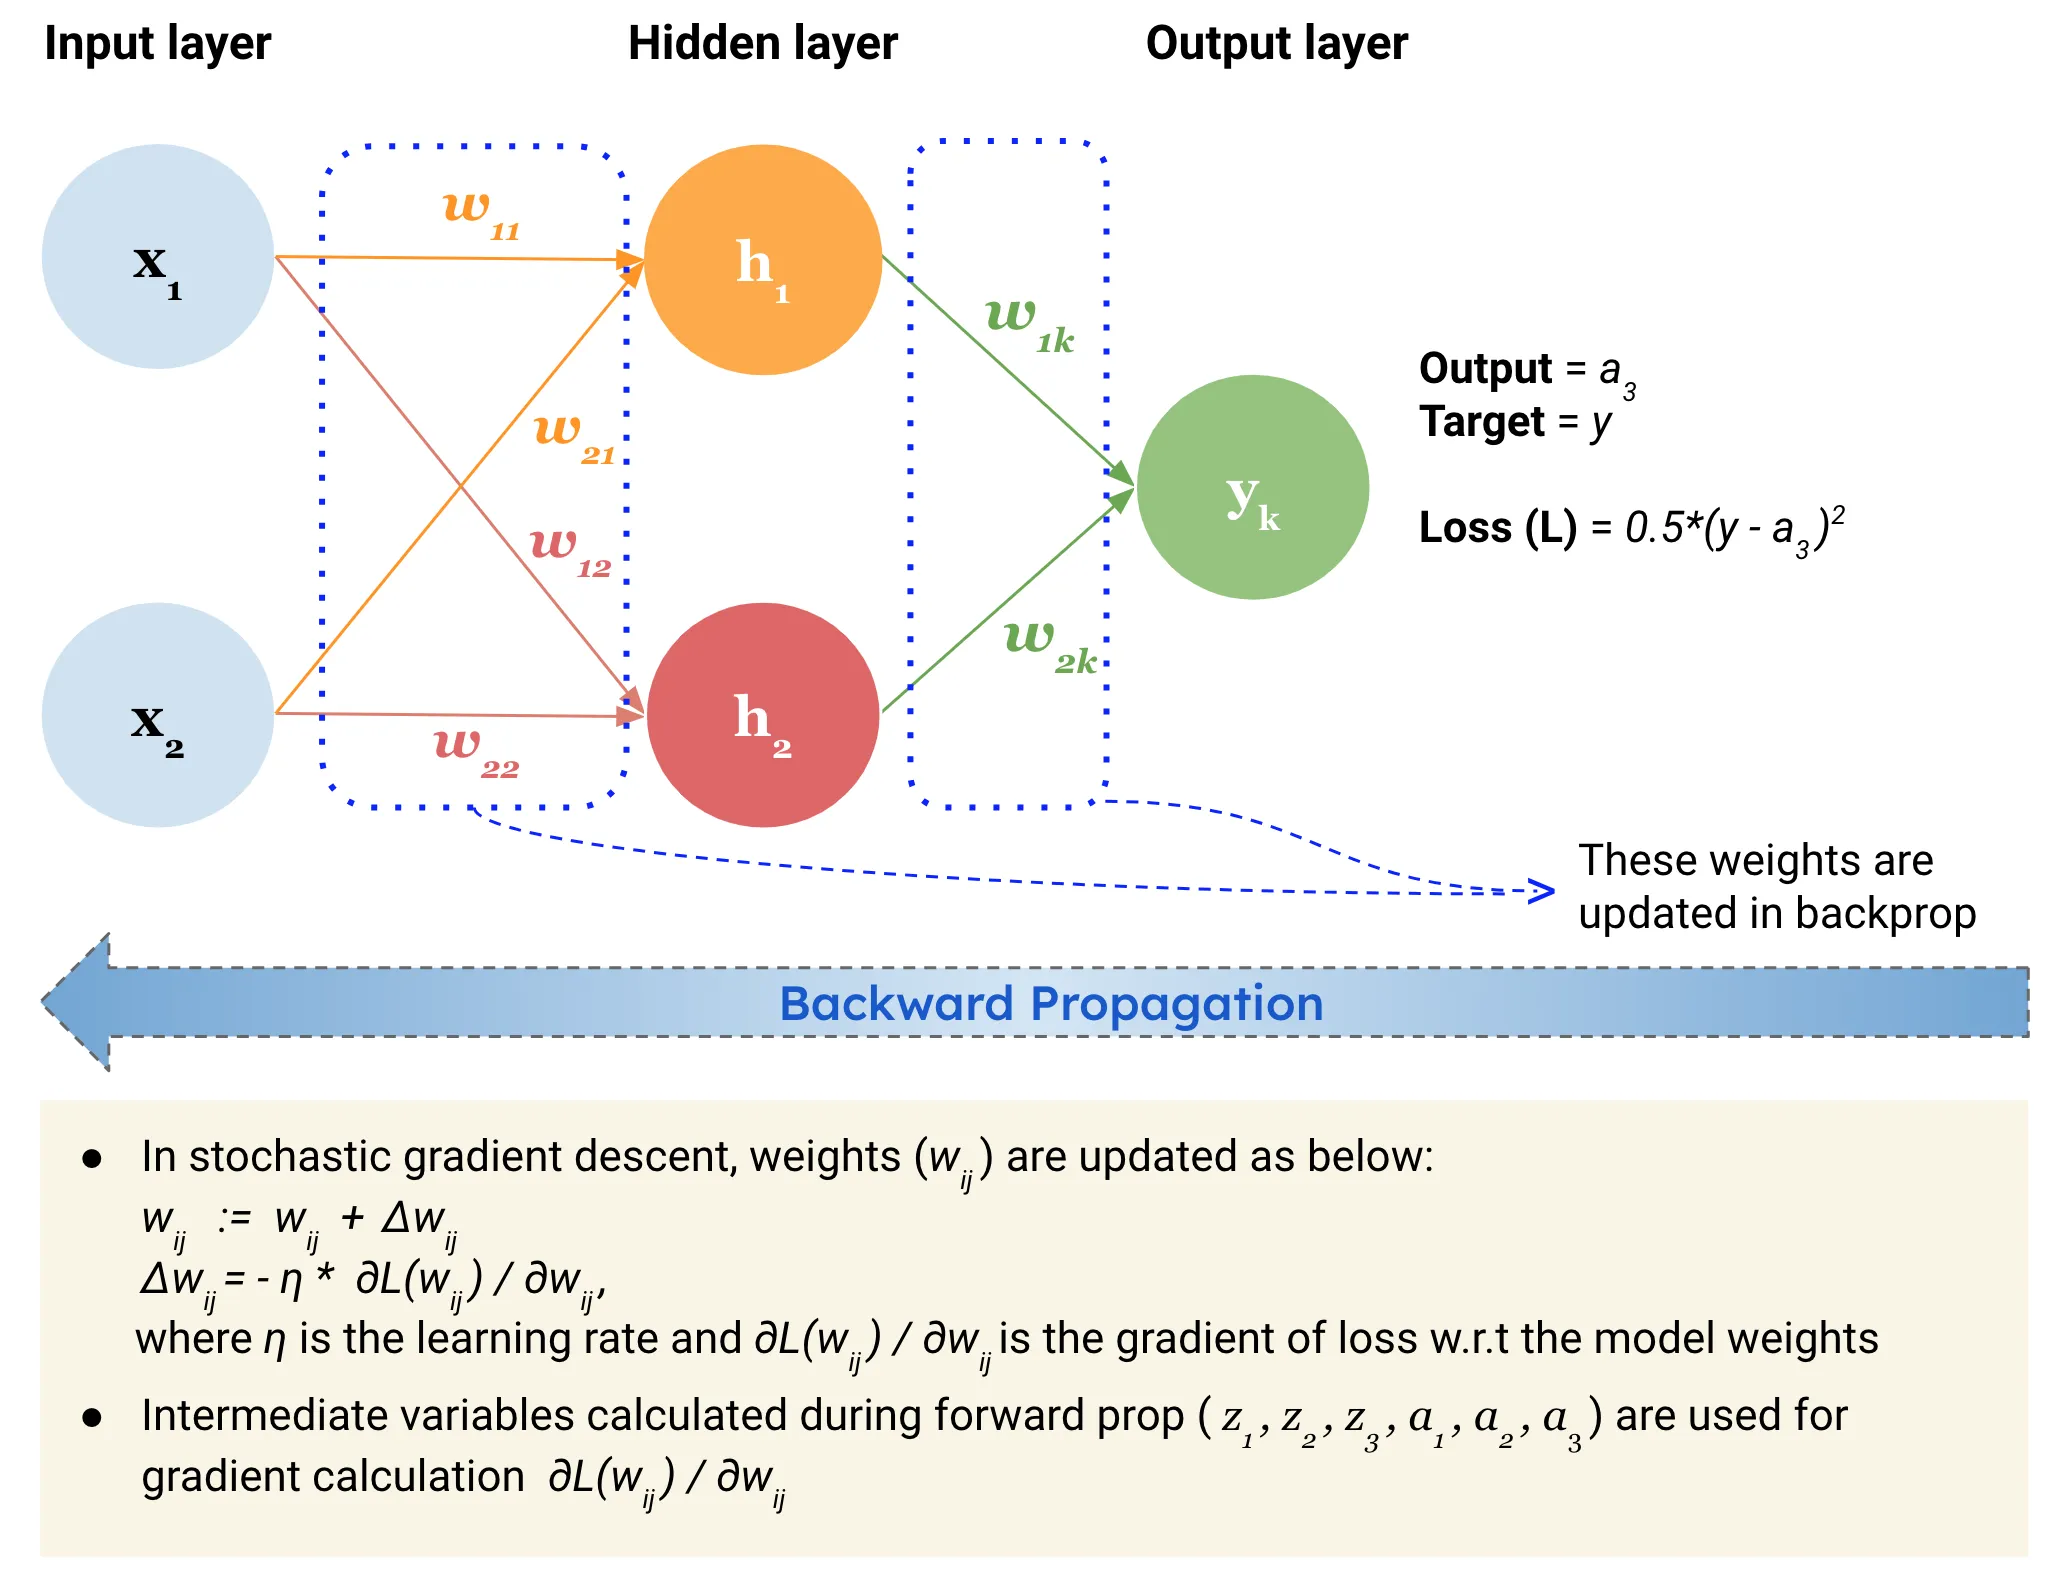](https://aiml.com/what-is-a-multilayer-perceptron-mlp/)

### Common Activation Functions
Modern neural networks commonly use the following activation functions:

1. **Binary Sigmoid** – compresses outputs to a range between 0 and 1.  
2. **Bipolar Sigmoid (Tanh)** – similar to sigmoid but outputs between -1 and 1.  
3. **ReLU (Rectified Linear Unit)** – outputs 0 for negative inputs and linear for positive ones.   
4. **Softmax** – converts raw outputs into probabilities that sum to 1 (used in multi-class classification output layers).


In [20]:
from sklearn.neural_network import MLPClassifier


#### 2.3.1 Binary Sigmoid Activation (`logistic`)

[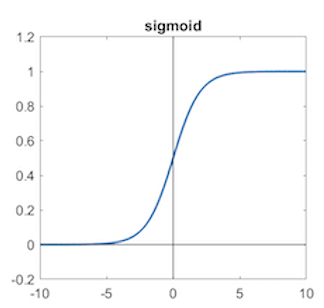](https://www.cs.cmu.edu/~bhiksha/courses/deeplearning/Spring.2019/archive-f19/www-bak11-22-2019/document/note/hwnotes/HW1p1.html)

- **Formula:** $\sigma(x) = \frac{1}{1 + e^{-x}}$
- **Range:** (0, 1)
- **Idea:** Smoothly “squashes” values into the 0–1 range.
- **When to use:**  
  - Commonly used in the **output layer** for **binary classification** (e.g., yes/no, 0/1).  
  - Can also be used in **hidden layers** of smaller or shallower networks to introduce nonlinearity, though it is less common in deep networks due to **vanishing gradient** issues.
- **Notes:**  
  - Easy to interpret as probabilities.  
  - Can suffer from **vanishing gradients** for large or small input values.


MLP (Sigmoid / logistic) — Accuracy: 0.900


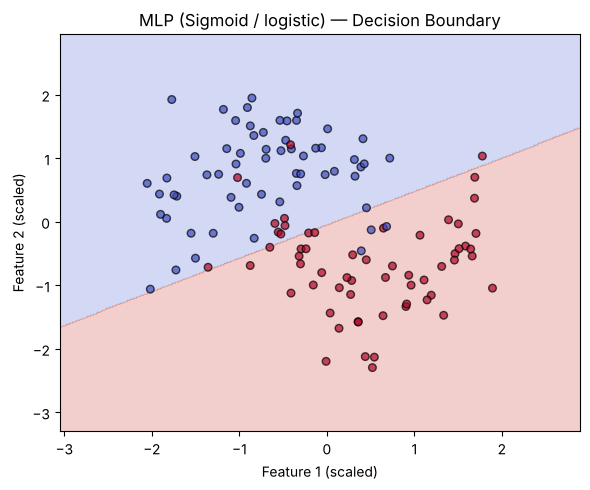

In [21]:
# --- MLP with Binary Sigmoid (logistic) activation ---
mlp_logistic = MLPClassifier(hidden_layer_sizes=(32, 32),
                             activation='logistic',
                             max_iter=1000,
                             random_state=42)
mlp_logistic.fit(X_train, y_train)
y_pred = mlp_logistic.predict(X_test)
acc_logistic = accuracy_score(y_test, y_pred)
print(f"MLP (Sigmoid / logistic) — Accuracy: {acc_logistic:.3f}")

plot_decision_boundary(mlp_logistic, X_test, y_test,
                       "MLP (Sigmoid / logistic) — Decision Boundary")


#### 2.3.2 Bipolar Sigmoid Activation (`tanh`)

[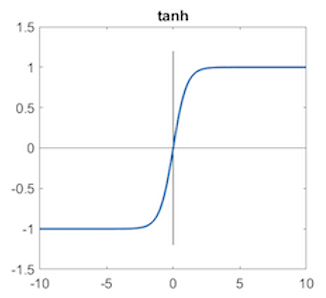](https://www.cs.cmu.edu/~bhiksha/courses/deeplearning/Spring.2019/archive-f19/www-bak11-22-2019/document/note/hwnotes/HW1p1.html)

- **Formula:** $\tanh(x)$
- **Range:** (-1, 1)
- **Idea:** Similar to sigmoid but **zero-centered**, making training faster and more stable. (Also called the *bipolar sigmoid*, since $\tanh(x)$ is a rescaled and shifted logistic function.)
- **When to use:**  
  - Often used in **hidden layers** for smaller or shallower networks.
- **Notes:**  
  - Outputs negative and positive values, helping gradients propagate symmetrically.

MLP (Tanh) — Accuracy: 0.908


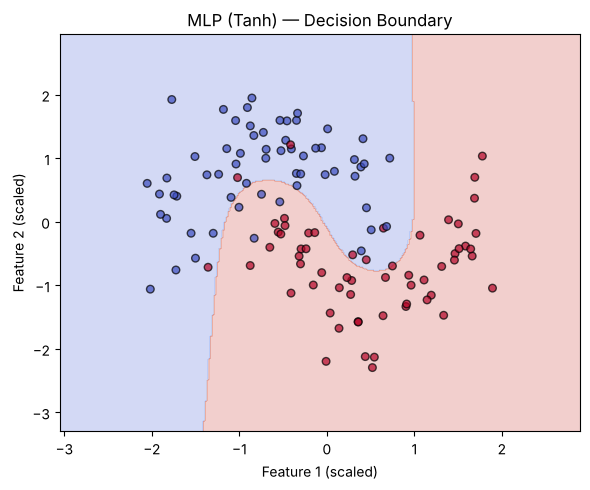

In [22]:
# --- MLP with Bipolar Sigmoid (tanh) activation ---
mlp_tanh = MLPClassifier(hidden_layer_sizes=(32, 32),
                         activation='tanh',
                         max_iter=1000,
                         random_state=42)
mlp_tanh.fit(X_train, y_train)
y_pred = mlp_tanh.predict(X_test)
acc_tanh = accuracy_score(y_test, y_pred)
print(f"MLP (Tanh) — Accuracy: {acc_tanh:.3f}")

plot_decision_boundary(mlp_tanh, X_test, y_test,
                       "MLP (Tanh) — Decision Boundary")


#### 2.3.3 ReLU Activation (`relu`)

[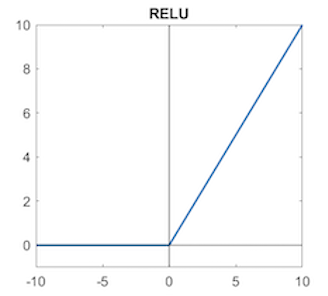](https://www.cs.cmu.edu/~bhiksha/courses/deeplearning/Spring.2019/archive-f19/www-bak11-22-2019/document/note/hwnotes/HW1p1.html)

- **Formula:** $\text{ReLU}(x) = \max(0, x)$
- **Range:** [0, ∞)
- **Idea:** Outputs zero for negative inputs and linear for positive inputs, allowing deep networks to train efficiently.
- **When to use:**  
  - **Default choice** for **hidden layers** in deep learning architectures.
- **Notes:**  
  - Computationally efficient and avoids vanishing gradients for positive inputs.  
  - Watch for “dead neurons” (outputs stuck at 0 for all inputs).


MLP (ReLU) — Accuracy: 0.900


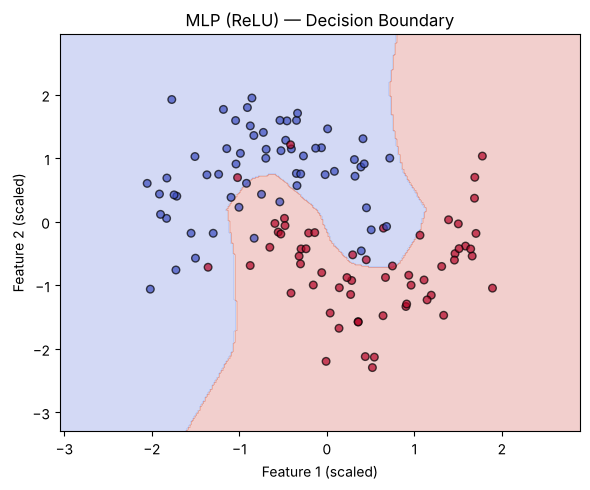

In [23]:
# --- MLP with ReLU activation ---
mlp_relu = MLPClassifier(hidden_layer_sizes=(32, 32),
                         activation='relu',
                         max_iter=1000,
                         random_state=42)
mlp_relu.fit(X_train, y_train)
y_pred = mlp_relu.predict(X_test)
acc_relu = accuracy_score(y_test, y_pred)
print(f"MLP (ReLU) — Accuracy: {acc_relu:.3f}")

plot_decision_boundary(mlp_relu, X_test, y_test,
                       "MLP (ReLU) — Decision Boundary")


#### 2.3.4 Softmax (for multi-class outputs)
- **Formula:** $\text{Softmax}(x_i) = \frac{e^{x_i}}{\sum_j e^{x_j}}$
- **Range:** (0, 1), and all outputs sum to 1.
- **Idea:** Converts raw network outputs (logits) into a **probability distribution** across classes.
- **When to use:**  
  - In the **output layer** of **multi-class classification** networks (e.g., 3 or more classes).
- **Notes:**  
  - Each neuron’s output represents the probability of a specific class.  
  - We have no softmax code to write: `MLPClassifier` applies it for us when there are 3+ classes. The cell below shows what it computes and what our binary model uses.


In [24]:
# Softmax by hand, and which output activation did our binary MLP use?
def softmax(z):
    z = z - np.max(z)            # subtract max for numerical stability
    e = np.exp(z)
    return e / e.sum()

logits = np.array([2.0, 1.0, 0.1])
print("Softmax:", softmax(logits).round(3), "| sums to", softmax(logits).sum())

print("Output activation used by our binary MLP:", mlp_relu.out_activation_)

Softmax: [0.659 0.242 0.099] | sums to 1.0
Output activation used by our binary MLP: logistic


### Summary: Activation Choices in MLPs

| Activation | Range | Common Use | Strengths | Weaknesses |
|:------------|:-------|:------------|:------------|:-------------|
| **Sigmoid (logistic)** | (0, 1) | Hidden or output layers (binary classification) | Simple, interpretable as probability; smooth output | Not zero-centered; vanishing gradients for large \|x\| |
| **Tanh** | (-1, 1) | Hidden layers (shallow or moderate-depth networks) | Zero-centered; faster convergence than sigmoid | Still prone to saturation at extremes |
| **ReLU** | [0, ∞) | Hidden layers (deep networks) | Fast training; avoids vanishing gradients; sparse activations | Can produce dead neurons (outputs stuck at 0) |
| **Softmax** | (0, 1), sum=1 | Output layer (multi-class classification) | Converts outputs to class probabilities; easy interpretation | Sensitive to large logits; not used for hidden layers |


### Comparing all models with the slide metrics
Now we can compare every supervised model on the **same test set** with more than accuracy. ROC curves (slide 11) need a continuous **score**, not just a label:
- Naïve Bayes and the MLPs give a probability with `predict_proba`.
- An SVM gives a signed distance to its boundary with `decision_function`. Any score that ranks points from "more negative" to "more positive" works for ROC and AUC, so this is fine.

The cell below builds a metrics table and overlays the ROC curves. The dashed diagonal is random guessing (AUROC = 0.5).

,Accuracy,Precision,Sensitivity,Specificity,FPR,F1,MCC,AUROC
Naive Bayes,0.892,0.927,0.850,0.933,0.067,0.887,0.786,0.965
SVM linear,0.892,0.927,0.850,0.933,0.067,0.887,0.786,0.962
SVM poly,0.867,0.958,0.767,0.967,0.033,0.852,0.748,0.961
SVM RBF,0.942,0.949,0.933,0.950,0.050,0.941,0.883,0.974
MLP sigmoid,0.900,0.944,0.850,0.950,0.050,0.895,0.804,0.962
MLP tanh,0.908,0.930,0.883,0.933,0.067,0.906,0.818,0.976
MLP ReLU,0.900,0.914,0.883,0.917,0.083,0.898,0.800,0.969


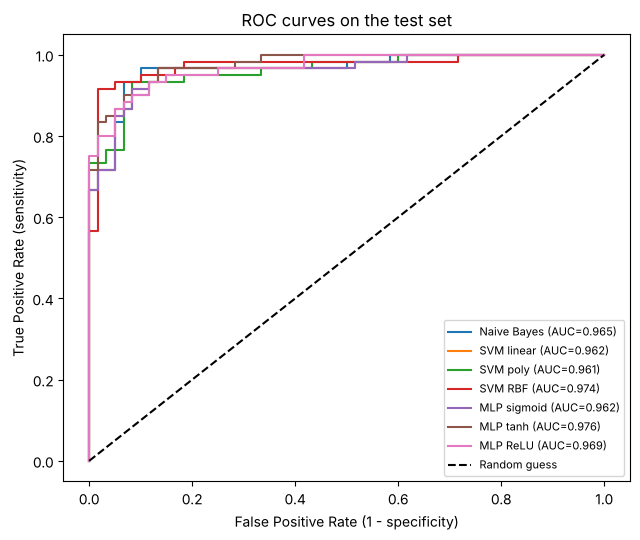

In [25]:
# === Compare all supervised models with the slide metrics ===
from sklearn.metrics import roc_curve

scored_models = {
    "Naive Bayes": (gnb,          gnb.predict_proba(X_test)[:, 1]),
    "SVM linear":  (svm_linear,   svm_linear.decision_function(X_test)),
    "SVM poly":    (svm_poly,     svm_poly.decision_function(X_test)),
    "SVM RBF":     (svm_rbf,      svm_rbf.decision_function(X_test)),
    "MLP sigmoid": (mlp_logistic, mlp_logistic.predict_proba(X_test)[:, 1]),
    "MLP tanh":    (mlp_tanh,     mlp_tanh.predict_proba(X_test)[:, 1]),
    "MLP ReLU":    (mlp_relu,     mlp_relu.predict_proba(X_test)[:, 1]),
}

table = pd.DataFrame({name: report_metrics(y_test, mdl.predict(X_test), score)
                      for name, (mdl, score) in scored_models.items()}).T
display(table.round(3))

plt.figure(figsize=(6.5, 5.5))
for name, (mdl, score) in scored_models.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    plt.plot(fpr, tpr, label=f"{name} (AUC={table.loc[name, 'AUROC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate (1 - specificity)")
plt.ylabel("True Positive Rate (sensitivity)")
plt.title("ROC curves on the test set")
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Reading the table and the plot**
- Which models have the highest AUROC? Is that ranking the same as the ranking by accuracy?
- Look at **precision vs. sensitivity** for each model. Does any model trade one for the other?
- Notice that the AUROC values are all close together, even though accuracy and MCC vary more. AUROC measures how well a model *ranks* positives above negatives across all thresholds, while accuracy depends on the one threshold we happened to use. Remember also that with 120 test points, differences in the third decimal place are not meaningful.

---
# Try It Yourself 3 — Are the activation differences real?

Earlier, one run of each activation gave `0.900` (sigmoid), `0.908` (tanh) and `0.900` (ReLU). Is tanh *really* better, or is that just luck of the random weight initialization?

**Your tasks**
1. For each activation in `['logistic', 'tanh', 'relu']`, train the same MLP (`hidden_layer_sizes=(32, 32)`, `max_iter=1000`) with **10 different `random_state` values** and record the test accuracy each time.
2. Report the **mean ± standard deviation** for each activation and draw a box plot or error-bar plot.
3. *(Extension)* Repeat for a few architectures, such as `(2,)`, `(8,)`, `(32, 32)`, `(64, 64, 64)` with your favorite activation. What happens to the decision boundary and the accuracy?

**Questions to answer in a markdown cell**
- (a) Are the differences between activations larger than the seed-to-seed variation?
- (b) Why does changing only `random_state` change the result at all?
- (c) Name one more thing you would vary to make the comparison more trustworthy (hint: look at how the data is split).

In [26]:
# YOUR CODE HERE (Try It Yourself 3)

**Your answers (a)–(c):**

*double-click to edit*

---
# Try It Yourself 4 — Move the threshold (slide 11 in action)

Most classifiers output a **score**, and the label comes from a **threshold** $\tau$: predict positive if the score is at least $\tau$. So far we used the default (about 0.5 for probabilities). The ROC curve on the slides is what you get by sweeping $\tau$.

**Your tasks** (use the Naïve Bayes probabilities `gnb.predict_proba(X_test)[:, 1]`)
1. For $\tau$ in `np.linspace(0.05, 0.95, 19)`, predict positive when the probability is at least $\tau$, and compute **precision**, **sensitivity**, and **specificity** (you may reuse `report_metrics`).
2. Plot the three metrics against $\tau$ on one figure.
3. Use [`roc_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html) to draw the ROC curve for the same scores, and mark the point that corresponds to $\tau = 0.5$.

**Questions to answer in a markdown cell**
- (a) As $\tau$ increases, what happens to sensitivity and to specificity? Why?
- (b) If a missed positive (FN) is much worse than a false alarm (FP), would you move $\tau$ up or down? What do you pay for it?
- (c) At very high $\tau$ the precision can look excellent. Why is that not a good reason to pick that threshold? (Hint: how many points still get predicted positive, and what would precision be if the answer were zero?)
- (d) If a classifier had an AUROC of 0.5, what would its ROC curve look like?

In [27]:
# YOUR CODE HERE (Try It Yourself 4)
# Hint: y_hat = (scores >= tau).astype(int), then report_metrics(y_test, y_hat)

**Your answers (a)–(d):**

*double-click to edit*

---

# Lab Wrap-Up

In this lab, we explored both **unsupervised** and **supervised** machine learning methods,  
starting with clustering algorithms that discover structure in unlabeled data,  
and moving to classification algorithms that learn to predict known labels.

### Comparing Unsupervised and Supervised Learning

| Aspect | **Unsupervised (Part 1)** | **Supervised (Part 2)** |
|:--------|:---------------------------|:-------------------------|
| Goal | Discover structure or groups | Predict known labels |
| Input | Features only ($X$) | Features and labels ($X$, $y$) |
| Uses | Exploratory analysis, dimensionality reduction | Prediction, decision-making |
| Examples | K-Means, GMM | Naïve Bayes, SVM, MLP |

### Summary of Models Covered

| Model | Type | Key Idea | Strengths | Limitations |
|:------|:------|:----------|:------------|:-------------|
| **K-Means** | Unsupervised | Partition by Euclidean distance | Simple, fast | Fails on non-spherical clusters |
| **GMM** | Unsupervised | Probabilistic clustering via Gaussian mixtures | Handles covariance, soft clustering | Assumes each cluster is a Gaussian ellipse (also struggles on moons) |
| **Naïve Bayes** | Supervised | Bayes’ rule with feature independence | Fast, interpretable | Independence assumption unrealistic |
| **SVM (Linear/Poly/RBF)** | Supervised | Maximize margin; kernel trick for nonlinearity | Robust, powerful boundaries | Sensitive to hyperparameters |
| **MLP** | Supervised | Neural network with learned nonlinear features | Very flexible | Requires tuning, slower training |

### Visual Summary: Decision Boundaries (conceptually)

| Model | Typical Boundary Shape | Learned From |
|:-------|:------------------------|:-------------|
| **K-Means** | Straight / convex (hard) | Distances |
| **GMM** | Elliptical / soft overlap | Probabilities |
| **Naïve Bayes** | Smooth, curved (quadratic for Gaussian NB) | Class likelihoods |
| **SVM (Linear)** | Straight line | Margins |
| **SVM (RBF)** | Smooth curved | Kernels |
| **MLP** | Arbitrary nonlinear | Learned transformations |

### Key Takeaways
- **Distance vs. Probability vs. Margin vs. Learning:**  
  You saw how ML models differ in how they *measure similarity* and *draw boundaries*.  
  - *K-Means* → Euclidean distance  
  - *GMM* → Mahalanobis distance (through covariance)  
  - *Naïve Bayes* → Probability of features given class  
  - *SVM* → Margin maximization (geometry)  
  - *MLP* → Learned nonlinear mapping
- **Accuracy is not the whole story:**  
  The confusion matrix (TP, FP, FN, TN) gives precision, sensitivity, specificity, F1, and MCC, and sweeping the threshold gives ROC/AUC. Choose the metric that matches which error costs more.
- **Evaluate fairly:**  
  Small test sets and single splits make small accuracy gaps unreliable. Tune on training data (cross-validation) and touch the test set once.
- **AI assistants are collaborators, not oracles:**  
  Code from U-M GPT or any LLM can look right and still be wrong. Read it, run it, and check it against something independent before you trust it.
